# 01 · Exploración y calidad de datos (EDA)

Antes de segmentar a nadie queremos entender bien qué hay en el CSV: qué es cada fila, cómo son los clientes, qué datos faltan y por qué, y qué columnas no nos sirven.

Lo hacemos pensando en para qué va a servir la segmentación: ofertas de vehículo, planes de mantenimiento, campañas de fidelización y comunicaciones. Cada vez que decidimos algo nos preguntamos si esa información ayuda a saber qué ofrecer, a quién y por qué canal.

Una manía que hemos tenido: casi todo lo que afirmamos en el texto va acompañado de un `assert` o de una tabla. Si los datos cambiaran y algo dejara de ser verdad, el notebook fallaría en vez de contar algo falso.

Lo que vamos a ver:
1. Qué es una fila
2. Estadísticas descriptivas
3. Nulos e inconsistencias, y qué hacemos con ellos
4. Columnas que descartamos
5. Cómo son los clientes
6. Resumen

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.ticker as mt
from src import config, clean
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
FIG = config.FIG_DIR; FIG.mkdir(parents=True, exist_ok=True)
REF_DATE = pd.Timestamp(config.REF_DATE)  # fecha de referencia común del equipo

# Estilo común para todos los gráficos
BLUE, INK, MUTED, GRID = '#2a78d6', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'figure.dpi': 110, 'axes.edgecolor': GRID, 'axes.labelcolor': MUTED, 'xtick.color': MUTED,
    'ytick.color': MUTED, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.titlecolor': INK, 'font.size': 9})

def barh(s, title, fmt='{:,.0f}', ax=None):
    # Barras horizontales finas con etiqueta directa del valor
    ax = ax or plt.subplots(figsize=(7, .32 * len(s) + .8))[1]
    ax.barh(s.index.astype(str), s.values, color=BLUE, height=.6)
    ax.invert_yaxis(); ax.set_title(title, loc='left'); ax.grid(axis='y', visible=False)
    for i, v in enumerate(s.values): ax.text(v, i, ' ' + fmt.format(v), va='center', color=INK, fontsize=8)
    ax.margins(x=.18); return ax

## 1. Carga y granularidad: ¿qué es una fila?

In [2]:
df = clean.load_raw()  # descarta el índice sin nombre de la exportación y parsea la fecha
n_cli, n_veh = df.client_id.nunique(), df.vehicle_id.nunique()
assert not df.duplicated(['client_id', 'vehicle_id']).any(), 'cada fila debería ser un par cliente-vehículo único'
print(f'{len(df):,} filas = pares cliente-vehículo únicos | {df.shape[1]} columnas | {n_cli:,} clientes | {n_veh:,} vehículos')

302,850 filas = pares cliente-vehículo únicos | 38 columnas | 173,456 clientes | 244,519 vehículos


In [3]:
# ¿Qué atributos son del CLIENTE (constantes en todas sus filas), del VEHÍCULO o de la RELACIÓN?
def pct_varying(key, cols):
    g = df.groupby(key)
    return pd.Series({c: (g[c].nunique(dropna=False) > 1).mean() * 100 for c in cols}).round(2)

client_cols = ['age_range', 'gender_derived', 'months_as_mb_customer', 'currently_connected_vehicles', 'finance_leasing_status',
               'consent_phone_communication_channel', 'consent_epost_communication_channel', 'consent_post_communication_channel',
               'country_code', 'zipcode', 'purchasing_power_per_inhabitant_eur']
vehicle_cols = ['model_series', 'vehicle_type', 'model_class', 'product_group', 'engine_concept', 'fuel_type', 'date_of_first_registration']
rel_cols = ['role', 'is_current_vehicle', 'workshop_visits_warranty_goodwill', 'trip_distance_average', 'operating_hours_total']
vc, vv, vr = pct_varying('client_id', client_cols), pct_varying('vehicle_id', vehicle_cols), pct_varying('vehicle_id', rel_cols)
assert (vc == 0).all() and (vv == 0).all() and (vr > 0).all()
display(vc.to_frame('% clientes con >1 valor'))
display(pd.concat([vv, vr]).to_frame('% vehículos con >1 valor'))

,% clientes con >1 valor
age_range,0.0
gender_derived,0.0
months_as_mb_customer,0.0
currently_connected_vehicles,0.0
finance_leasing_status,0.0
consent_phone_communication_channel,0.0
consent_epost_communication_channel,0.0
consent_post_communication_channel,0.0
country_code,0.0
zipcode,0.0


,% vehículos con >1 valor
model_series,0.00
vehicle_type,0.00
model_class,0.00
product_group,0.00
engine_concept,0.00
fuel_type,0.00
date_of_first_registration,0.00
role,6.85
is_current_vehicle,12.09
workshop_visits_warranty_goodwill,11.98


El dataset mezcla tres niveles de información:

- **Del cliente:** edad, antigüedad, consentimientos, leasing y zona. No cambian nunca entre las filas de un mismo cliente.
- **Del vehículo:** modelo, clase, motor y fecha de matriculación. No cambian entre las filas de un mismo coche.
- **De la relación cliente-coche:** rol, si está activo, visitas al taller y telemetría. Estas sí cambian cuando varias personas comparten coche (el dueño y alguien que lo conduce, por ejemplo).

Como a quien se le manda la oferta es a una persona, segmentamos **a nivel cliente** y resumimos sus coches con agregados (cuántos tiene, de qué gama, si son eléctricos...). Esa tabla la construimos en el reto 2 (`02a_features_cliente`).

In [4]:
rows_per_client = df.groupby('client_id').size()
buckets = pd.cut(rows_per_client, [0, 1, 2, 5, 19, np.inf], labels=['1', '2', '3-5', '6-19', '≥20'])
t = pd.DataFrame({'clientes': buckets.value_counts().sort_index(),
                  'filas': rows_per_client.groupby(buckets, observed=False).sum()})
t['% clientes'] = (t.clientes / t.clientes.sum() * 100).round(2); t['% filas'] = (t.filas / t.filas.sum() * 100).round(2)
display(t)
heavy = rows_per_client[rows_per_client >= 20]
print(f'{len(heavy)} clientes ({len(heavy)/n_cli:.2%}) acumulan {heavy.sum():,} filas ({heavy.sum()/len(df):.1%}). Máximo: {rows_per_client.max()} vehículos.')
rt = df[df.client_id.isin(heavy.index)].role_type.value_counts(normalize=True).mul(100).round(1)
print('role_type de sus filas (%):', rt.to_dict())

,clientes,filas,% clientes,% filas
1,127081,127081,73.26,41.96
2,31271,62542,18.03,20.65
3-5,11703,40272,6.75,13.30
6-19,2493,23778,1.44,7.85
≥20,908,49177,0.52,16.24


908 clientes (0.52%) acumulan 49,177 filas (16.2%). Máximo: 561 vehículos.
role_type de sus filas (%): {'B2C': 92.5, 'B2B': 7.5}


Aquí hay algo a tener en cuenta: un 0,5 % de los clientes (908) se lleva el 16 % de las filas. Tienen entre 20 y 561 vehículos, así que por volumen son flotas, renting o concesionarios. Y curiosamente el 92,5 % de sus filas figuran como B2C, o sea que el campo de empresa no los detecta.

Si no hacemos nada, dominan cualquier estadística por filas y en el clustering arrastrarían a los centroides. Lo que decidimos (lo aplicamos en el reto 2):

- En el modelo entran con el resto, pero el número de vehículos se recorta para que no pesen de más (en la práctica, cualquiera con 10 o más coches cuenta como 10).
- Les ponemos un flag, `is_heavy_account`, para poder reconocerlos al describir los segmentos.
- No les forzamos un segmento propio a mano: si son tan distintos, K-Means ya los separará.

## 2. Estadísticas descriptivas

In [5]:
num = df.select_dtypes('number')
display(num.describe(percentiles=[.01, .5, .99]).T.round(2))

,count,mean,std,min,1%,50%,99%,max
model_series,302850.0,267.88,150.21,107.00,117.00,243.00,907.00,9.100000e+02
months_as_mb_customer,302846.0,43.87,26.89,0.00,0.00,39.00,115.00,1.200000e+02
currently_connected_vehicles,302850.0,2.15,3.53,0.00,0.00,1.00,19.00,2.100000e+01
workshop_visits_warranty_goodwill,302850.0,1.75,2.43,0.00,0.00,1.00,10.00,4.400000e+01
purchasing_power_per_inhabitant_eur,283763.0,46481.17,17294.53,19701.53,24291.65,46165.64,106183.57,1.483537e+05
purchasing_power_per_household_eur,283763.0,104766.27,41597.55,45087.34,51698.89,102246.51,246174.02,3.424980e+05
population,283836.0,19664.85,36803.22,0.00,470.00,7132.00,220313.00,2.207940e+05
trip_distance_average,116993.0,16.16,10.67,1.00,2.84,14.02,49.39,3.000000e+02
trip_distance_median,123020.0,6.62,7.77,1.00,1.00,7.50,27.50,3.000000e+02
trip_distance_all_counter,123020.0,2351.70,2768.20,0.00,0.00,1593.00,11404.62,8.907800e+04


In [6]:
cat_cols = ['age_range', 'gender_derived', 'country_code', 'product_group', 'engine_concept', 'fuel_type', 'role', 'role_type',
            'finance_leasing_status', 'is_current_vehicle', 'consent_phone_communication_channel',
            'consent_epost_communication_channel', 'consent_post_communication_channel']
display(pd.DataFrame({c: [df[c].nunique(), df[c].mode()[0], round(df[c].value_counts(normalize=True).iloc[0] * 100, 1),
                          round(df[c].isna().mean() * 100, 1)] for c in cat_cols},
                     index=['n_categorías', 'moda', '% moda (sin nulos)', '% nulos']).T)

,n_categorías,moda,% moda (sin nulos),% nulos
age_range,6,45-54,22.5,0.0
gender_derived,2,male,83.0,11.2
country_code,2,CH,63.7,0.0
product_group,4,P,84.4,0.0
engine_concept,4,COMBUSTION,58.4,44.4
fuel_type,7,DIESEL,28.9,59.0
role,5,OWNER,87.3,0.0
role_type,2,B2C,98.2,0.0
finance_leasing_status,4,never_active,58.3,0.0
is_current_vehicle,2,True,59.5,0.0


## 3. Calidad de datos: nulos e inconsistencias

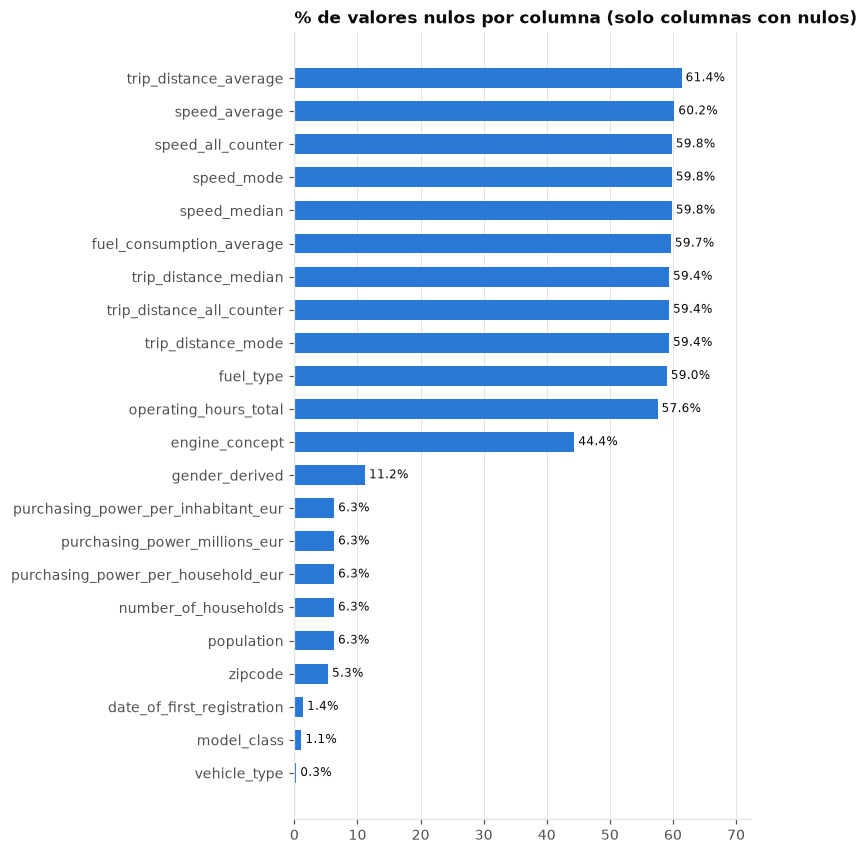

In [7]:
nulls = df.isna().mean().mul(100).round(2)
nulls = nulls[nulls > 0].sort_values(ascending=False)
barh(nulls, '% de valores nulos por columna (solo columnas con nulos)', fmt='{:.1f}%')
plt.tight_layout(); plt.savefig(FIG / '01_nulos.png'); plt.show()

Los nulos se agrupan en **cuatro bloques**, cada uno con su causa. Los vamos mirando uno a uno.

### 3.1 Telemetría (~57-61 % de nulos): no es un error, es que no hay coche conectado

In [ ]:
# Hay telemetría si el coche tiene alguna de las cuatro medias de uso (misma definición que en el reto 2)
tele_cols = ['trip_distance_average', 'speed_average', 'fuel_consumption_average', 'operating_hours_total']
df['has_telemetry'] = df[tele_cols].notna().any(axis=1)
display(df.groupby('role').has_telemetry.mean().mul(100).round(1).to_frame('% filas con telemetría'))
display(df.groupby('is_current_vehicle').has_telemetry.mean().mul(100).round(1).to_frame('% filas con telemetría'))
assert df.loc[df.engine_concept.eq('ELECTRIC'), 'fuel_consumption_average'].isna().all()  # un eléctrico no consume combustible
print(f'Clientes con telemetría en al menos un vehículo: {df.groupby("client_id").has_telemetry.any().mean():.1%}')

- La telemetría aparece sobre todo cuando el cliente es dueño (OWNER) o usuario (USER) de un coche **conectado**: en torno a la mitad de esas filas la tienen. En DRIVER, LEGACY y TEMP_USER casi no hay (3-13 %).
- `fuel_consumption_average` está vacío en todos los eléctricos, y tiene sentido: un eléctrico no gasta combustible. Es un nulo lógico.
- Solo el 60 % de los clientes tiene algún dato de uso. Rellenar el 40 % restante sería inventarnos cómo conducen.

Qué hacemos:
- Un flag `has_telemetry`, que ya dice algo del cliente: está conectado o no.
- Comparamos el modelo con y sin telemetría en el reto 3. Lo que vemos aquí apunta a dejarla **fuera del modelo base**: si rellenamos con la mediana a 4 de cada 10 clientes, los ponemos a todos en el mismo punto y K-Means se inventa un grupo.
- La usaremos para describir a los clientes que sí la tienen (por ejemplo, planes de mantenimiento según los km o las horas de uso).

### 3.2 Motorización (`engine_concept` 44 %, `fuel_type` 59 %): recuperable en parte

In [9]:
display(pd.crosstab(df.engine_concept.fillna('NULO'), df.fuel_type.fillna('NULO')))
assert (df.engine_concept.isna() <= df.fuel_type.isna()).all()  # si falta el motor, falta también el combustible
# El modelo comercial determina el motor: aprender vehicle_type -> engine_concept de las filas conocidas
known = df[df.engine_concept.notna()]
purity = known.groupby('vehicle_type').engine_concept.agg(lambda s: s.value_counts(normalize=True).iloc[0])
mapping = known.groupby('vehicle_type').engine_concept.agg(lambda s: s.mode()[0])
recovered = df.loc[df.engine_concept.isna(), 'vehicle_type'].map(mapping).notna()
print(f'Pureza media vehicle_type -> motor: {purity.mean():.1%} ({(purity == 1).mean():.1%} de los tipos son 100 % puros)')
print(f'Nulos de motor recuperables por mapeo: {recovered.mean():.1%} ({recovered.sum():,} filas)')

fuel_type,DIESEL,"DIESEL,ELECTRIC",ELECTRIC,NULO,PETROL,"PETROL,ELECTRIC",PETROL_PLUS,"PETROL_PLUS,ELECTRIC"
engine_concept,,,,,,,,
COMBUSTION,28475,0,0,43915,14422,0,11612,0
ELECTRIC,0,0,20944,0,0,0,0,0
MILD_HYBRID,7418,0,0,29,17946,0,2362,0
NULO,0,0,0,134390,0,0,0,0
PLUGIN_HYBRID,0,8604,0,411,0,7371,0,4951


Pureza media vehicle_type -> motor: 98.9% (94.7% de los tipos son 100 % puros)
Nulos de motor recuperables por mapeo: 53.7% (72,224 filas)


- `fuel_type` no aporta nada que no diga `engine_concept`: cuando falta el motor falta también el combustible, y encima tiene más huecos. Lo quitamos.
- La versión comercial (`vehicle_type`, p. ej. "GLC 220 d 4MATIC") casi siempre tiene el mismo motor, así que podemos usarla para rellenar huecos.

Un matiz con la pureza: el 98,9 % de arriba es la media **por versión**. Si ponderamos por filas baja al 95,5 %, porque hay versiones con muchas filas que son ambiguas (la "C 220 d" ha sido combustión o mild hybrid según la generación). Por eso en el reto 2 solo usamos las versiones con al menos un 90 % de pureza y 5 filas conocidas. Así recuperamos algo menos de la mitad de los nulos (un 47 %, frente al 54 % de arriba), pero sin meter motores dudosos. Los coches de la familia EQ, que son todos eléctricos, se rellenan aparte, y lo que queda se marca como `UNKNOWN`.

Para marketing la electrificación es clave: campañas de paso al eléctrico, carga, wallbox...

### 3.3 Socioeconómicos (~6 %), género (11 %) y otros nulos puntuales

In [10]:
print('Filas con CP pero sin datos socioeconómicos:', (df.zipcode.notna() & df.purchasing_power_per_inhabitant_eur.isna()).sum())
assert not (df.zipcode.isna() & df.purchasing_power_per_inhabitant_eur.notna()).any()
print('Longitud de CP (AT y CH usan 4 dígitos):', df.zipcode.dropna().str.len().value_counts().to_dict())
print('Filas con population == 0:', (df.population == 0).sum())
display(df.groupby('role').gender_derived.apply(lambda s: s.isna().mean() * 100).round(1).to_frame('% género nulo'))
print('months_as_mb_customer nulos:', df.months_as_mb_customer.isna().sum(), '| model_class nulos:', df.model_class.isna().sum(),
      '| vehicle_type nulos:', df.vehicle_type.isna().sum(), '| fecha matriculación nula:', df.date_of_first_registration.isna().sum())

Filas con CP pero sin datos socioeconómicos: 2952
Longitud de CP (AT y CH usan 4 dígitos): {4: 286710, 6: 2, 5: 1, 7: 1, 9: 1}
Filas con population == 0: 73


,% género nulo
role,
DRIVER,4.1
LEGACY,11.9
OWNER,9.2
TEMP_USER,38.1
USER,36.2


months_as_mb_customer nulos: 4 | model_class nulos: 3369 | vehicle_type nulos: 922 | fecha matriculación nula: 4182


| Columna | Causa probable | Qué hacemos |
|---|---|---|
| Poder adquisitivo / población (6,3 % de filas) | CP que falta o que no está en la tabla socioeconómica | Rellenamos con la **mediana de su país**, porque AT y CH tienen niveles muy distintos. No añadimos un flag de "imputado": que falte el CP es un fallo del dato, no algo que diga cómo es el cliente |
| `population == 0` (73 filas) | CP sin población residente (zonas industriales, apartados de correos) | Lo tratamos como nulo y se rellena igual |
| CP con longitud ≠ 4 (5 filas) | Error de captura | Nada: el código postal no entra al modelo |
| `gender_derived` (11 %) | Es **inferido**. Falla más en USER y TEMP_USER (~37 %) | Lo dejamos como desconocido y no entra al modelo. Rellenarlo sería inventarse un dato sensible |
| `model_class` (1,1 %), `vehicle_type` (0,3 %) | Modelos sin catalogar (sobre todo eléctricos nuevos) | Grupo `OTRO` |
| Fecha de matriculación (1,4 %) | Falta en origen | La antigüedad del coche se rellena con la mediana. Afecta a menos del 1 % de los clientes y no compensa algo más fino |
| `months_as_mb_customer` (4 filas) | Residual | Mediana |

### 3.4 Inconsistencias y valores extremos

In [11]:
g = df.groupby('client_id')
conn_mismatch = (g.currently_connected_vehicles.first() != g.is_current_vehicle.sum()).sum()
print(f'Clientes donde connected_vehicles != sum(is_current): {conn_mismatch} de {n_cli:,}')
checks = {
    'role_type B2B == role DRIVER': (df.role_type.eq('B2B') == df.role.eq('DRIVER')).all(),
    'connected_vehicles == sum(is_current) en >99,99 % clientes': conn_mismatch / n_cli < 1e-4,
    'matriculación <= fecha del análisis (2026-10-15)': (df.date_of_first_registration.dropna() <= '2026-10-15').all(),
    'speed_mode contiene listas (empates)': df.speed_mode.dropna().str.contains(',').any(),
}
display(pd.Series(checks).to_frame('verificado'))
assert all(checks.values())

Clientes donde connected_vehicles != sum(is_current): 4 de 173,456


,verificado
role_type B2B == role DRIVER,True
"connected_vehicles == sum(is_current) en >99,99 % clientes",True
matriculación <= fecha del análisis (2026-10-15),True
speed_mode contiene listas (empates),True


In [12]:
d = df.date_of_first_registration
print('Matriculaciones anteriores a 2009:', (d.dt.year < 2009).sum(), '| rango:', d.min().date(), '→', d.max().date())
display(pd.DataFrame({
    'regla': ['workshop_visits > 20', 'speed_average > 150 km/h', 'trip_distance_average >= 200 km', 'fuel_consumption >= 40 l/100km',
              'operating_hours_total > 10.000 h', 'speed_all_counter > p99'],
    'filas': [(df.workshop_visits_warranty_goodwill > 20).sum(), (df.speed_average > 150).sum(), (df.trip_distance_average >= 200).sum(),
              (df.fuel_consumption_average >= 40).sum(), (df.operating_hours_total > 1e4).sum(),
              (df.speed_all_counter > df.speed_all_counter.quantile(.99)).sum()]}))

Matriculaciones anteriores a 2009: 33 | rango: 1987-01-14 → 2026-10-02


,regla,filas
0,workshop_visits > 20,95
1,speed_average > 150 km/h,26
2,trip_distance_average >= 200 km,37
3,fuel_consumption >= 40 l/100km,132
4,operating_hours_total > 10.000 h,21
5,speed_all_counter > p99,1217


- **B2B es exactamente DRIVER.** Solo hay un concepto de empresa (el conductor de flota), el 1,8 % de las filas. `role` y `role_type` dicen lo mismo, así que nos basta con un flag de empresa.
- **`currently_connected_vehicles` cuadra con `is_current_vehicle`**: coinciden en todos los clientes salvo 4 (seguramente un desfase de actualización). Son la misma información, así que nos quedamos con una sola.
- **Las `*_mode` mezclan tipos:** son texto, a veces con listas cuando hay empate, y los valores vienen en tramos (3, 7,5, 15...). Lo útil ya está en las medias.
- **Extremos:** son pocos casos y poco creíbles (velocidad media de más de 150 km/h, consumos de 50 l/100 km). Como K-Means trabaja con distancias le afectarían mucho, así que recortamos en los percentiles 1-99 y usamos logaritmo en las variables con cola larga.
- **Matriculaciones de 1987-2008** (33 filas): clásicos o youngtimers (G-Class, SL). En Mercedes son normales, no las tratamos como error.

### 3.5 Antigüedad como cliente: un pico artificial en 36 meses

In [13]:
tenure = df.drop_duplicates('client_id').set_index('client_id')
tv = tenure.months_as_mb_customer.value_counts().sort_index()
print('Clientes por antigüedad 33-39 meses:', tv.loc[33:39].astype(int).to_dict())
neighbours = tv.loc[[33, 34, 35, 37, 38, 39]].mean()
assert tv.loc[36] > 5 * neighbours  # 36 meses es un pico anómalo, no una tendencia
newest = df.groupby('client_id').date_of_first_registration.max()
age36 = (REF_DATE - newest[tenure.months_as_mb_customer.eq(36)]).dt.days.median() / 365.25
age_all = (REF_DATE - newest).dt.days.median() / 365.25
print(f'36 meses: {tv.loc[36]:,} clientes ({tv.loc[36]/n_cli:.1%}), ~{tv.loc[36]/neighbours:.0f}x sus vecinos. '
      f'Edad mediana de su coche más nuevo: {age36:.1f} años vs {age_all:.1f} del total')
print(f'Clientes con 0 meses (recién llegados): {tv.loc[0]:,} ({tv.loc[0]/n_cli:.1%}) | antigüedad máxima: {tv.index.max():.0f} meses')

Clientes por antigüedad 33-39 meses: {33.0: 2069, 34.0: 2174, 35.0: 2619, 36.0: 21179, 37.0: 2770, 38.0: 2739, 39.0: 2298}


36 meses: 21,179 clientes (12.2%), ~9x sus vecinos. Edad mediana de su coche más nuevo: 6.9 años vs 4.1 del total
Clientes con 0 meses (recién llegados): 7,254 (4.2%) | antigüedad máxima: 120 meses


- El **12 % de los clientes** tiene exactamente 36 meses de antigüedad, unas 9 veces más que los meses de al lado, y sus coches son más viejos que la media. Huele a valor por defecto: clientes que ya existían antes de que arrancara el sistema conectado y a los que se les puso un valor fijo.
- Para ellos la antigüedad **no mide su fidelidad real** (seguramente es mayor). Si la usamos tal cual, el clustering podría montar un grupo de "clientes de 3 años" que no existe.
- En el otro extremo, el máximo es 120 meses. Parece un tope a 10 años, pero hay muy pocos casos y no nos preocupa.

Qué hacemos: un flag `tenure_is_default` (antigüedad = 36) para que el modelo sepa que ese 36 no es un 36 de verdad. Pensamos en calcular una antigüedad alternativa con la matriculación de su coche más antiguo, pero lo descartamos: si el coche era de segunda mano, su fecha no dice nada de cuándo llegó el cliente a la marca.

## 4. Columnas excluidas y por qué

In [14]:
display(df[['purchasing_power_per_inhabitant_eur', 'purchasing_power_per_household_eur', 'purchasing_power_millions_eur',
             'population', 'number_of_households']].corr(method='spearman').round(2))
print('Cardinalidad: vehicle_type', df.vehicle_type.nunique(), '| model_series', df.model_series.nunique(), '| model_class', df.model_class.nunique())

,purchasing_power_per_inhabitant_eur,purchasing_power_per_household_eur,purchasing_power_millions_eur,population,number_of_households
purchasing_power_per_inhabitant_eur,1.00,0.96,0.05,-0.16,-0.17
purchasing_power_per_household_eur,0.96,1.00,-0.08,-0.28,-0.30
purchasing_power_millions_eur,0.05,-0.08,1.00,0.97,0.96
population,-0.16,-0.28,0.97,1.00,1.00
number_of_households,-0.17,-0.30,0.96,1.00,1.00


Cardinalidad: vehicle_type 1436 | model_series 88 | model_class 42


| Columna | Por qué la descartamos |
|---|---|
| (índice sin nombre) | Índice de la exportación. `clean.load_raw` ya lo quita |
| `client_id`, `vehicle_id` | Identificadores. Sirven para agrupar, nunca como feature |
| `zipcode` | Identificador geográfico con miles de valores; lo que nos interesa de la zona ya entra por el poder adquisitivo y la población |
| `purchasing_power_per_household_eur` | Dice lo mismo que el valor por habitante (0,96) |
| `purchasing_power_millions_eur`, `number_of_households` | Dicen lo mismo que la población (0,96-1,00): son básicamente población × poder adquisitivo |
| `fuel_type` | Repite `engine_concept` y tiene más huecos (§3.2) |
| `role_type` | Idéntico a `role == DRIVER` (§3.4); nos basta un flag de empresa |
| `vehicle_type`, `model_series` | Demasiado detalle (1.436 y 88 valores). Se resumen en grupos de `model_class`. `vehicle_type` solo lo usamos para rellenar el motor |
| `trip_distance_mode`, `speed_mode`, `*_median` | Texto con listas y valores en tramos; repiten las medias |
| `trip_distance_all_counter`, `speed_all_counter` | Cuentan cuántos datos se han recogido, no cómo se usa el coche, y llegan a 1,45·10⁹ |

Y lo que **sí nos quedamos** de esos grupos:
- **Poder adquisitivo por habitante**, que en el reto 2 pasamos a relativo a su país. En Suiza es mucho más alto que en Austria y, si no, solo nos diría "es suizo".
- **Población**, como pista de si la zona es urbana o rural. Es verdad que describe la zona y no al cliente, pero lo mismo pasa con el poder adquisitivo, y dónde vive alguien influye en qué coche tiene y cómo lo usa.
- **`currently_connected_vehicles`**, una sola vez (§3.4).
- **Telemetría:** no la descartamos; entra como flag y la probamos en el reto 3.

## 5. Cómo son los clientes de Mercedes-Benz

Todo lo de arriba era por filas. Para describir a los clientes hay que contarlos de uno en uno; si no, los que tienen muchos coches cuentan varias veces (por filas parece que el 42 % ha usado leasing y por clientes es el 29 %). Usamos la misma tabla de clientes que construimos en el reto 2 (`src/clean.py`), así todos los notebooks dan las mismas cifras.

In [ ]:
cli = clean.build_client_table(df)  # la misma tabla que en 02a_features_cliente
cli['electrified'] = cli.share_plugin_ev > 0  # algún eléctrico o híbrido enchufable
assert len(cli) == n_cli and cli.index.is_unique
print(cli.shape)  # sin enseñar filas sueltas: son datos reales de clientes
cli.describe(include='all').T

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(11, 6.5))
order = config.AGE_ORDER
barh(cli.age_range.value_counts(normalize=True).reindex(order) * 100, 'Rango de edad (% clientes)', '{:.1f}%', ax=axs[0, 0])
barh(cli.gender_derived.fillna('desconocido').value_counts(normalize=True) * 100, 'Género inferido (% clientes)', '{:.1f}%', ax=axs[0, 1])
barh(cli.country_code.value_counts(normalize=True) * 100, 'País (% clientes)', '{:.1f}%', ax=axs[1, 0])
barh(cli.finance_leasing_status.value_counts(normalize=True) * 100, 'Financiación / leasing (% clientes)', '{:.1f}%', ax=axs[1, 1])
plt.tight_layout(); plt.savefig(FIG / '01_demografia.png'); plt.show()

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
axs[0].hist(cli.tenure_months.dropna(), bins=40, color=BLUE, rwidth=.9); axs[0].set_title('Antigüedad como cliente (meses)', loc='left')
axs[1].hist(cli.ppi.dropna(), bins=50, color=BLUE, rwidth=.9); axs[1].set_title('Poder adquisitivo por habitante (€)', loc='left')
axs[1].xaxis.set_major_formatter(mt.FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
axs[2].hist(cli.main_vehicle_age.dropna().clip(upper=20), bins=40, color=BLUE, rwidth=.9); axs[2].set_title('Antigüedad del coche principal (años)', loc='left')
for a in axs: a.set_ylabel('clientes')
plt.tight_layout(); plt.savefig(FIG / '01_numericas.png'); plt.show()
print('Mediana poder adquisitivo por habitante:', cli.groupby('country_code').ppi.median().round(0).to_dict())

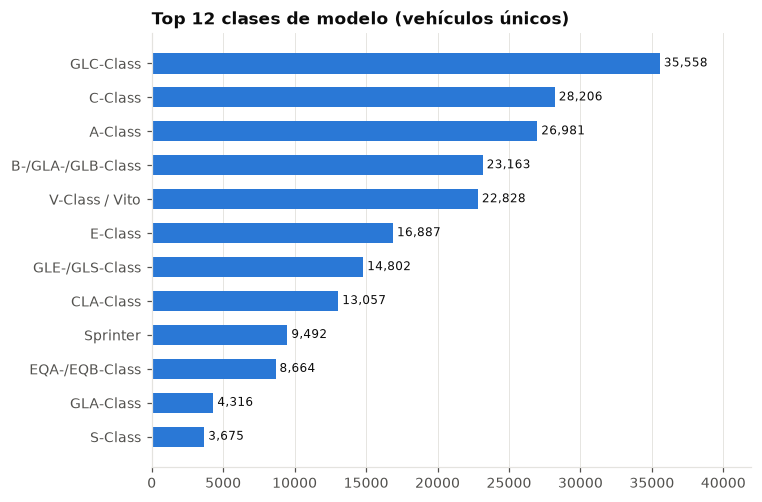

In [18]:
barh(df.drop_duplicates('vehicle_id').model_class.value_counts().head(12), 'Top 12 clases de modelo (vehículos únicos)')
plt.tight_layout(); plt.savefig(FIG / '01_modelos.png'); plt.show()

In [ ]:
kpi = pd.Series({
    'Clientes con 1 solo vehículo': (cli.n_vehicles == 1).mean(),
    'Sin vehículo activo hoy (riesgo de fuga)': (cli.has_current_vehicle == 0).mean(),
    'Con algún eléctrico o enchufable': cli.electrified.mean(),
    'Con leasing activo': cli.finance_leasing_status.str.startswith('active').mean(),
    'Con leasing ya terminado (renovación)': cli.finance_leasing_status.eq('was_active').mean(),
    'Sin visitas al taller en garantía': (cli.workshop_visits_mean == 0).mean(),
    'Con telemetría (conectados)': cli.has_telemetry.mean(),
    'Consentimiento email': cli.consent_epost.mean(), 'Consentimiento teléfono': cli.consent_phone.mean(),
    'Consentimiento correo postal': cli.consent_post.mean(), 'Sin ningún consentimiento': (cli.n_consents == 0).mean(),
    'Empresa (B2B)': cli.is_b2b.mean(),
    'Cuentas de 20 o más vehículos': cli.is_heavy_account.mean()}) * 100
barh(kpi.round(1), 'Indicadores de negocio (% de clientes)', '{:.1f}%')
plt.tight_layout(); plt.savefig(FIG / '01_kpis_negocio.png'); plt.show()

In [ ]:
# Cruces que nos interesan para marketing
display((pd.crosstab(cli.age_range, cli.electrified, normalize='index')[True] * 100).reindex(order).round(1).to_frame('% con electrificado'))
display((pd.crosstab(cli.age_range, cli.finance_leasing_status, normalize='index') * 100).reindex(order).round(1))
display(cli.groupby('country_code')[['electrified', 'has_telemetry', 'consent_phone', 'consent_post']].mean().mul(100).round(1))

## 6. Resumen de lo que hemos visto

Las cifras son por cliente (173.456), sacadas de las salidas de arriba.

### ¿Cómo son los clientes?

| Tema | Lo que vemos | Qué significa para marketing |
|---|---|---|
| Mercado | 66 % Suiza y 34 % Austria. Poder adquisitivo mediano por habitante: 51.000 € en Suiza y 30.000 € en Austria | Son dos mercados con niveles muy distintos; ofertas y precios hay que pensarlos por país |
| Edad | Base madura: el 61 % tiene 45 años o más y el 20 % más de 65. Menores de 25, solo un 5 % | Fidelizar al cliente sénior es lo prioritario; el joven es un nicho para captar (compactos, renting) |
| Género (inferido) | 65 % hombres, 18 % mujeres y un 17 % que no sabemos | Sirve para describir, no para dirigir campañas |
| Vehículos | El 73 % solo ha tenido un coche. Un 0,5 % son cuentas de 20 o más | La palanca principal es la recompra; las flotas van por otro canal |
| Gama | Mandan los SUV (GLC, GLA/GLB, GLE/GLS) y los C y A. Hay un bloque importante de furgonetas (Vito/V-Class, Sprinter, Citan) | Particular con SUV y profesional con furgoneta piden mensajes distintos |
| Electrificación | El 23 % tiene algún eléctrico o enchufable, y **crece con la edad**: del 12 % en menores de 25 al 28 % en 55-64. En Austria es el 31 % y en Suiza el 20 % | Al contrario de lo que esperábamos, el que se pasa al eléctrico es maduro y con dinero, no joven. En Suiza hay recorrido |
| Financiación | El 26 % tiene un leasing activo (el pico, un 33 %, en 35-44 años) y un 3 % lo ha terminado. El 84 % de los mayores de 65 nunca ha usado leasing | Los leasing terminados son una ventana clara para renovar; los mayores pagan al contado |
| Actividad | El 10 % no tiene ningún coche activo | Riesgo de fuga, o clientes a recuperar |
| Taller | El 29 % no ha ido al taller en garantía | Público para planes de mantenimiento y recordatorios |
| Conectividad | El 60 % tiene telemetría | Mantenimiento según uso real, pero solo en esa parte |
| Consentimientos | Email 98 %, teléfono 86 %, correo 85 %. Nadie tiene todos cerrados | El email llega a casi todos; el canal no distingue a unos clientes de otros |

### ¿Qué problemas de calidad hemos encontrado y qué hacemos?

| Problema | Qué hacemos |
|---|---|
| Mezcla de niveles (cliente, vehículo y relación) | Una fila por cliente |
| Cuentas de 20 o más coches que lo distorsionan todo | Recortamos el nº de vehículos en el modelo y las marcamos con un flag para describirlas |
| Telemetría que falta en el 40 % de los clientes (no tienen coche conectado) | Flag `has_telemetry`; fuera del modelo base y lo comprobamos en el reto 3 |
| Motor y combustible vacíos (44 % y 59 %) | Rellenamos el motor por versión comercial (solo versiones fiables) y por familia EQ; el resto `UNKNOWN`. Fuera `fuel_type` |
| Poder adquisitivo y población vacíos (6 %), población 0, CP raros | Mediana de su país; la población 0 cuenta como vacía |
| Género inferido vacío (11 %) | Desconocido y fuera del modelo |
| Columnas que repiten lo mismo (`role_type`, `fuel_type`, poder adquisitivo ×3, vehículos conectados) | Una sola por concepto |
| `*_mode` con listas y valores en tramos | Fuera |
| Extremos poco creíbles | Recorte p1-p99 y log en colas largas |
| Antigüedad = 36 meses en el 12 % (valor por defecto) | Flag `tenure_is_default` |

Todo esto lo llevamos a la práctica en el reto 2 (`02a_features_cliente` y `02b_pipeline`).